Generate Dataset for each user

In [1]:
import os
import cv2
from mtcnn import MTCNN  


# Initialize MTCNN detector
face_detector = MTCNN()

# Function to detect and crop faces using MTCNN
def face_cropped(img):
    # Optionally, resize the frame to speed up detection:
    # resized_img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5)
    # faces = face_detector.detect_faces(resized_img)
    faces = face_detector.detect_faces(img)  # Detect faces in the original image
    if not faces:
        return None  # No face detected

    # Use the first detected face
    face = faces[0]
    x, y, w, h = face["box"]
    # Ensure the coordinates are within image bounds
    x, y = max(x, 0), max(y, 0)
    cropped_face = img[y:y + h, x:x + w]  # Crop the detected face
    return cropped_face

# Function to collect dataset for multiple users
def generate_dataset():
    user_id = input("Enter User ID or Name: ").strip()  # Get user ID
    if user_id == "":
        Exception("The ID is empty")
    user_dir = os.path.join("data", user_id)
    os.makedirs(user_dir, exist_ok=True)  # Create directory for user

    cap = cv2.VideoCapture(0)  # Open webcam
    img_id = 0  # Image counter

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        cropped = face_cropped(frame)  # Detect and crop face once per frame
        if cropped is not None:
            img_id += 1  # Increment image ID
            try:
                face = cv2.resize(cropped, (200, 200))  # Resize face
            except Exception as e:
                
                print("Resize error:", e)
                continue
            face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)  # Convert to grayscale

            file_name_path = os.path.join(user_dir, f"user.{user_id}.{img_id}.jpg")
            cv2.imwrite(file_name_path, face)  # Save image

            # Show image count on screen
            display_face = face.copy()
            cv2.putText(display_face, str(img_id), (50, 50), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 255, 0), 2)
            cv2.imshow("Cropped Face", display_face)

        # Stop if Enter is pressed (ASCII 13) or 200 images are collected
        if cv2.waitKey(1) == 13 or img_id == 200:
            break

    cap.release()
    cv2.destroyAllWindows()
    print(f"Data collection for {user_id} completed. {img_id} images saved.")

# Call the function
generate_dataset()


Data collection for 9 completed. 200 images saved.


train classifier

In [2]:
import cv2
import numpy as np
import os
from PIL import Image

def train_classifier(data_dir="data"):
    faces = []
    ids = []

    for user in os.listdir(data_dir):
        user_path = os.path.join(data_dir, user)

        if not os.path.isdir(user_path):  # Skip non-folder items
            continue

        image_paths = [os.path.join(user_path, f) for f in os.listdir(user_path) if f.endswith(".jpg")]

        for image_path in image_paths:
            img = Image.open(image_path).convert("L")  # Convert to grayscale
            image_np = np.array(img, "uint8")  # Convert to NumPy array

            try:
                user_id = int(os.path.basename(image_path).split(".")[1])  # Extract ID (convert to int)
            except ValueError:
                print(f"Skipping invalid filename: {image_path}")
                continue

            faces.append(image_np)
            ids.append(user_id)

    ids = np.array(ids)

    # ✅ Use the correct OpenCV module
    clf = cv2.face.LBPHFaceRecognizer_create()
    clf.train(faces, ids)
    clf.write("classifier.xml")
    print("✅ Training completed. Classifier saved as 'classifier.xml'.")

# Call the function
train_classifier("data")


✅ Training completed. Classifier saved as 'classifier.xml'.


real time testing

In [3]:
import cv2
import numpy as np
import os
from mtcnn import MTCNN  # Import MTCNN for face detection

def recognize_face():
    # Initialize the MTCNN face detector
    detector = MTCNN()
    
    # Load the trained face recognition model
    clf = cv2.face.LBPHFaceRecognizer_create()
    clf.read("classifier.xml")
    
    # Open the camera (try 0 if 1 doesn't work)
    cap = cv2.VideoCapture(0)
    
    while True:
        ret, img = cap.read()
        
        if not ret or img is None:
            print("⚠️ Error: Could not capture image from camera.")
            continue  # Skip this iteration and try again
        
        # Detect faces using MTCNN
        faces = detector.detect_faces(img)
        
        for face in faces:
            x, y, w, h = face['box']  # Extract bounding box coordinates
            x, y = abs(x), abs(y)  # Ensure values are positive
            
            cv2.rectangle(img, (x, y), (x + w, y + h), (255, 255, 255), 2)
            
            # Convert detected face region to grayscale for recognition
            gray_face = cv2.cvtColor(img[y:y+h, x:x+w], cv2.COLOR_BGR2GRAY)
            gray_face = cv2.resize(gray_face, (160, 160))  # Resize for consistency
            
            # Recognize face
            id, pred = clf.predict(gray_face)
            confidence = int(100 * (1 - pred / 300))
            
            if confidence > 78:
                text = f"User_{id}" + " authorized"
            else:
                text = "unauthorized"
                print(confidence)
            cv2.putText(img, text, (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 1, cv2.LINE_AA)
        
        cv2.imshow("Face Recognition", img)
        
        if cv2.waitKey(1) == 13:  # Press "Enter" to exit
            break
    
    cap.release()
    cv2.destroyAllWindows()

# Run face recognition
recognize_face()


62
67
56
70
62
69
66
65
67
65
63
69
66
67
57
72
60
62
78
75
77
61
78
68
69
66
70
67
62
67


KeyboardInterrupt: 

evaluation and Testing with testing dataset

In [ ]:
import cv2
import numpy as np
import os
from mtcnn import MTCNN
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Initialize MTCNN face detector
detector = MTCNN()

# Load trained face recognition model
clf = cv2.face.LBPHFaceRecognizer_create()
clf.read("classifier.xml")

# Define test dataset path
test_dir = "test_dataset"
labels = {}  # Store labels for mapping

# Prepare test data
X_test, y_true, y_pred, confidence_scores = [], [], [], []

for label, user in enumerate(os.listdir(test_dir)):  # Iterate through each user folder
    print(label, user )
    labels[label] = user  # Map label to user name
    user_dir = os.path.join(test_dir, user)

    for img_name in os.listdir(user_dir):  # Iterate through images
        img_path = os.path.join(user_dir, img_name)
        img = cv2.imread(img_path)

        if img is None:
            continue  # Skip unreadable images

        faces = detector.detect_faces(img)

        for face in faces:
            x, y, w, h = face['box']
            x, y = abs(x), abs(y)  # Ensure positive values
            gray_face = cv2.cvtColor(img[y:y+h, x:x+w], cv2.COLOR_BGR2GRAY)
            gray_face = cv2.resize(gray_face, (160, 160))

            # Predict user
            id, pred = clf.predict(gray_face)
            confidence = int(100 * (1 - pred / 300))

            # Determine if recognized correctly
            y_true.append(int(user))  # Actual label
            y_pred.append(id if confidence > 75 else -1)  # Predicted label (-1 for unknown)
            confidence_scores.append(confidence)
            
# Compute accuracy metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=1)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=1)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=1)
conf_matrix = confusion_matrix(y_true, y_pred)

# Print results
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print("Confusion Matrix:\n", conf_matrix)
confidence_scores.sort()
print(confidence_scores[0], "\n" ,confidence_scores[-1], "\n" , np.mean(confidence_scores))

0 -1
1 1
2 2
Accuracy: 0.82
Precision: 0.93
Recall: 0.82
F1 Score: 0.86
Confusion Matrix:
 [[102   0   0  63]
 [  0 171  23   0]
 [  0  14 186   0]
 [  0   0   0   0]]
58 
 89 
 82.02146690518784


Visualization

C:\Users\Yousuf\AppData\Local\Temp\ipykernel_27656\150197823.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette="viridis")


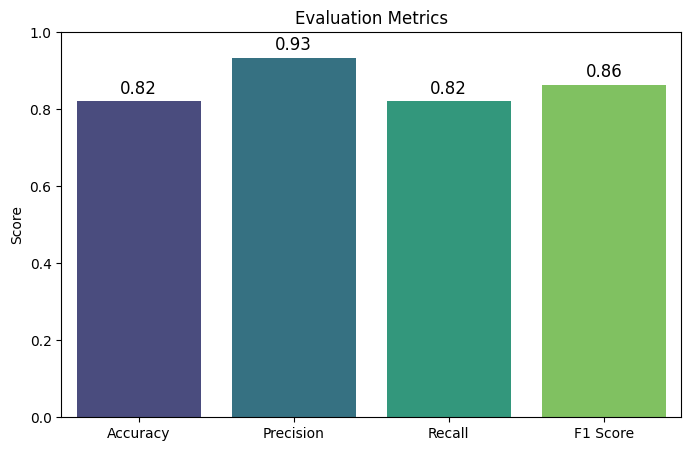

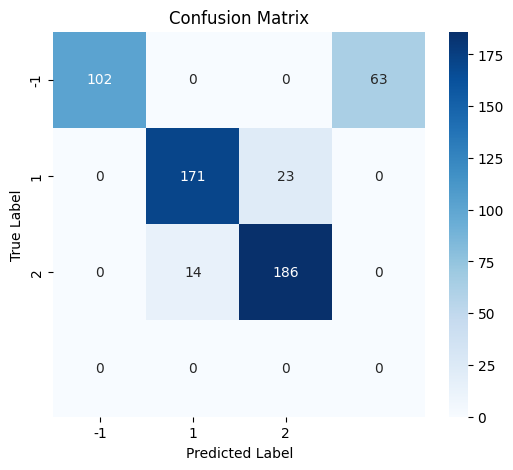

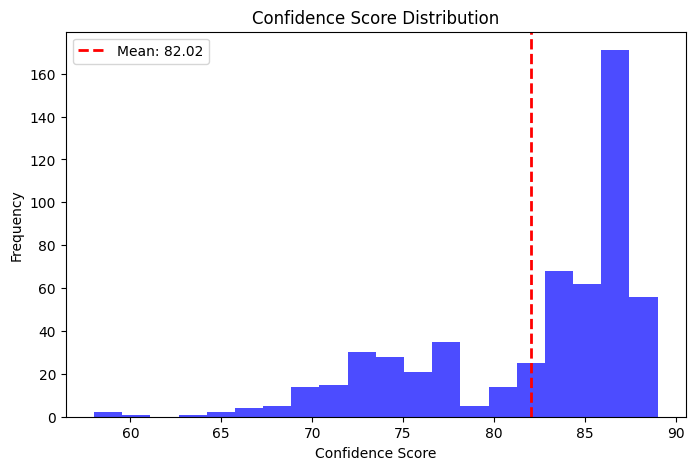

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization for Accuracy, Precision, Recall, and F1 Score
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
sns.barplot(x=metrics, y=values, palette="viridis")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Evaluation Metrics")
for i, v in enumerate(values):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=12)
plt.show()

# Visualization for Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels.values(), yticklabels=labels.values())
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

# Visualization for Confidence Scores
plt.figure(figsize=(8, 5))
plt.hist(confidence_scores, bins=20, color='blue', alpha=0.7)
plt.axvline(np.mean(confidence_scores), color='red', linestyle='dashed', linewidth=2, label=f"Mean: {np.mean(confidence_scores):.2f}")
plt.xlabel("Confidence Score")
plt.ylabel("Frequency")
plt.title("Confidence Score Distribution")
plt.legend()
plt.show()


In [4]:
# Extract TP, FP, FN, TN from Confusion Matrix
TP = np.diag(conf_matrix)  # True Positives are the diagonal elements
FP = np.sum(conf_matrix, axis=0) - TP  # False Positives (column sum - TP)
FN = np.sum(conf_matrix, axis=1) - TP  # False Negatives (row sum - TP)
TN = np.sum(conf_matrix) - (TP + FP + FN)  # True Negatives

# Print extracted values
print(f"True Positives (TP): {TP}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"True Negatives (TN): {TN}")


True Positives (TP): [102 171 186   0]
False Positives (FP): [ 0 14 23 63]
False Negatives (FN): [63 23 14  0]
True Negatives (TN): [394 351 336 496]


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (3,) and arg 1 with shape (4,).

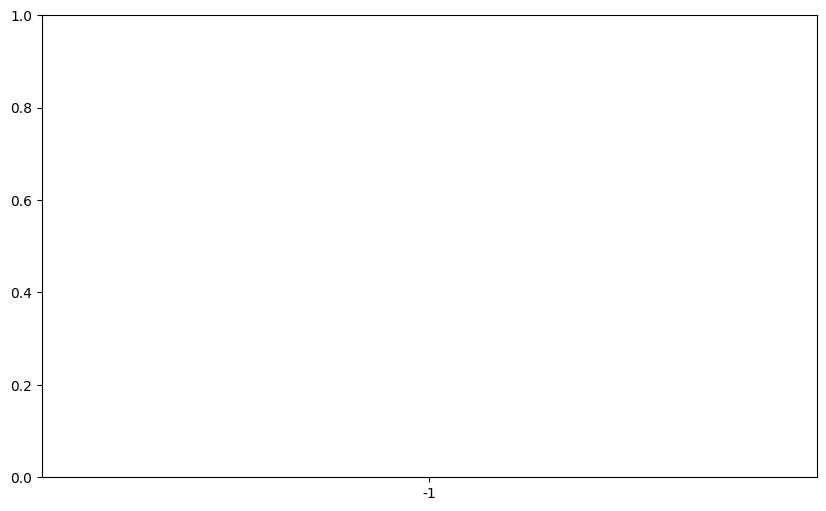

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Labels for the bars
categories = list(labels.values())

plt.figure(figsize=(10, 6))

# Stack bars for each class
plt.bar(categories, TP, label="True Positive (TP)", color='green', alpha=0.8)
plt.bar(categories, FP, bottom=TP, label="False Positive (FP)", color='red', alpha=0.6)
plt.bar(categories, FN, bottom=TP + FP, label="False Negative (FN)", color='orange', alpha=0.7)
plt.bar(categories, TN, bottom=TP + FP + FN, label="True Negative (TN)", color='blue', alpha=0.5)

plt.xlabel("Classes")
plt.ylabel("Count")
plt.title("TP, FP, FN, TN per Class")
plt.legend()
plt.xticks(rotation=45)  # Rotate labels if needed
plt.show()
